![Estimer le prix des logements à Bordeaux Métropole](https://raw.githubusercontent.com/yayefatou-lam/prix-logements-bordeaux/main/assets/banner.png)

# Prix des logements à Bordeaux Métropole · 2. Exploration

**Yaye Fatou Lam** · projet personnel de data science · notebook 2 sur 3

| $\color{#B5562F}{\mathbf{-12\,\%}}$ | $\color{#B5562F}{\mathbf{27/28}}$ | $\color{#B5562F}{\mathbf{\times\,2{,}3}}$ |
|:---:|:---:|:---:|
| prix médian au m² des maisons, 2022 → 2025 | communes où les maisons sont plus chères au m² | écart de prix au m² des appartements entre Ambès et Bordeaux |

> $\color{#2F76AE}{\textbf{Sommaire}}$
>
> 1. Évolution des prix
> 2. Écarts entre communes
> 3. Carte des prix
> 4. Prix et surface
> 5. Bilan

Avant de modéliser, on cherche ce qui fait varier le prix au m² : le temps, le lieu, le type de logement et la surface. Chaque constat oriente le choix des variables du modèle.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Racine du dépôt : les notebooks sont dans notebooks/
RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.affichage import fr, tableau

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ventes = pd.read_parquet(RACINE / "data" / "ventes_bm_2021_2025.parquet")
ASSETS = RACINE / "assets"
ASSETS.mkdir(exist_ok=True)

# Palette du projet (style « Pierre de Bordeaux »)
COULEURS = {"Maison": "#B5562F", "Appartement": "#2F76AE"}
ENCRE, GRIS, FILET = "#2F3437", "#7C7368", "#E6DED2"

# Style commun : axes discrets, grille horizontale légère
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": GRIS, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS, "axes.grid": True,
    "axes.grid.axis": "y", "grid.color": FILET, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": ENCRE,
    "axes.titlelocation": "left", "legend.frameon": False,
})

# Milliers séparés par une espace : 4 000 et non 4,000
milliers = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
n_types = ventes["type_local"].value_counts()
print(f"{fr(len(ventes))} ventes : {fr(n_types['Appartement'])} appartements et {fr(n_types['Maison'])} maisons")

57 244 ventes : 35 046 appartements et 22 198 maisons


## $\color{#B5562F}{\mathbf{1}}$ &nbsp; Évolution des prix

In [2]:
ventes["annee"] = ventes["date_mutation"].dt.year

# Prix médian au m² et nombre de ventes, par année et par type
par_annee = (ventes.groupby(["annee", "type_local"])["prix_m2"]
                   .agg(**{"Prix médian (€/m²)": "median", "Ventes": "size"})
                   .unstack("type_local")
                   .rename_axis(index="Année", columns=[None, None]))
tableau(par_annee, gras=[2022, 2025], legende="En gras : le pic de 2022 et la dernière année.")

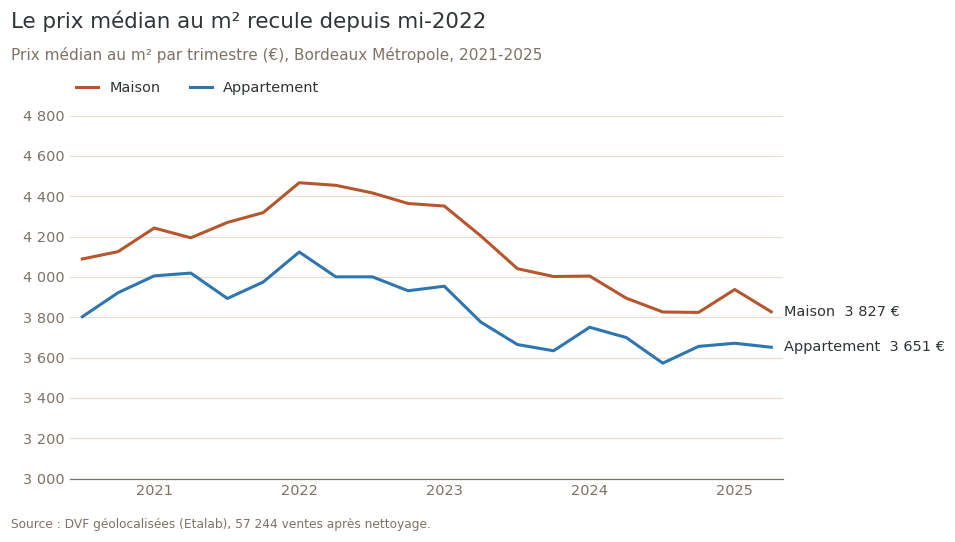

In [3]:
# Prix médian au m² par trimestre (la médiane résiste mieux aux valeurs extrêmes)
trim = (ventes.groupby([ventes["date_mutation"].dt.to_period("Q"), "type_local"])["prix_m2"]
              .median().unstack("type_local"))
trim.index = trim.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 5))
for type_local, couleur in COULEURS.items():
    serie = trim[type_local]
    ax.plot(serie.index, serie, color=couleur, lw=2, label=type_local)
    ax.annotate(f"{type_local}  {serie.iloc[-1]:,.0f} €".replace(",", " "),
                (serie.index[-1], serie.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=ENCRE, fontsize=9.5)

# Axe vertical à partir de 3 000 € pour ne pas exagérer la baisse
ax.set_ylim(3000, 4800)
ax.yaxis.set_major_formatter(milliers)
ax.tick_params(length=0, labelsize=9.5)
ax.set_xlim(trim.index[0] - pd.Timedelta(days=30), trim.index[-1] + pd.Timedelta(days=30))
ax.set_xticks(pd.to_datetime([f"{a}-07-01" for a in range(2021, 2026)]))
ax.set_xticklabels(range(2021, 2026))

fig.text(0.02, 0.95, "Le prix médian au m² recule depuis mi-2022", fontsize=14, color=ENCRE, va="top")
fig.text(0.02, 0.885, "Prix médian au m² par trimestre (€), Bordeaux Métropole, 2021-2025",
         fontsize=10, color=GRIS, va="top")
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.02), ncol=2, fontsize=9.5,
          handlelength=1.5, labelcolor=ENCRE)
nb = f"{len(ventes):,}".replace(",", " ")
fig.text(0.02, 0.01, f"Source : DVF géolocalisées (Etalab), {nb} ventes après nettoyage.",
         color=GRIS, fontsize=8)
fig.subplots_adjust(left=0.08, right=0.8, top=0.76, bottom=0.1)
fig.savefig(ASSETS / "evolution_prix_m2.png", facecolor="white", dpi=150)
plt.show()

> $\color{#55623F}{\textbf{Constat}}$
>
> Le prix médian au m² culmine mi-2022 puis recule d'environ **12 %** pour les maisons et **9 %** pour les appartements jusqu'en 2025.
> Le nombre de ventes chute d'environ 30 % entre 2021 et 2024, puis remonte en 2025.
> Le marché bouge : c'est pourquoi le modèle sera testé sur 2025, une année qu'il n'aura jamais vue.

## $\color{#B5562F}{\mathbf{2}}$ &nbsp; Écarts entre communes

In [4]:
# Prix médian au m² et nombre de ventes par commune et par type
par_commune = (ventes.groupby(["nom_commune", "type_local"])["prix_m2"]
                     .agg(**{"Prix médian (€/m²)": "median", "Ventes": "size"})
                     .unstack("type_local")
                     .rename_axis(index="Commune", columns=[None, None])
                     .sort_values(("Prix médian (€/m²)", "Appartement")))
fragiles = par_commune.index[(par_commune["Ventes"] < 30).any(axis=1)]
tableau(par_commune, ocre=fragiles,
        legende="En ocre : communes avec moins de 30 ventes pour au moins un type (médiane fragile).")

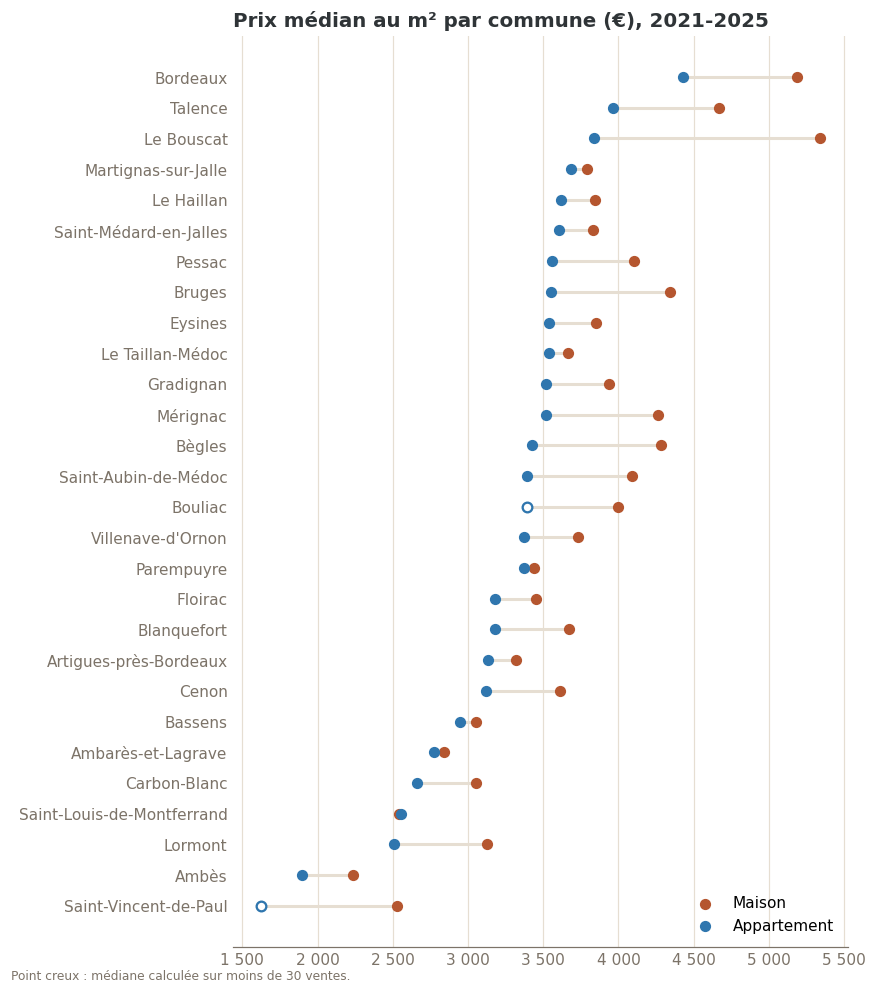

In [5]:
fig, ax = plt.subplots(figsize=(8, 9))
y = range(len(par_commune))
appart = par_commune[("Prix médian (€/m²)", "Appartement")]
maison = par_commune[("Prix médian (€/m²)", "Maison")]

# Trait reliant les deux types dans chaque commune
ax.hlines(y, appart, maison, color=FILET, lw=2, zorder=1)

# Médianes fragiles (moins de 30 ventes) affichées en point creux
yy = pd.Series(list(y), index=par_commune.index)
for type_local, couleur in COULEURS.items():
    prix = par_commune[("Prix médian (€/m²)", type_local)]
    fiable = par_commune[("Ventes", type_local)] >= 30
    ax.scatter(prix[fiable], yy[fiable], color=couleur, s=40, label=type_local, zorder=2)
    ax.scatter(prix[~fiable], yy[~fiable], facecolor="white", edgecolor=couleur, s=40, lw=1.5, zorder=2)

ax.set_yticks(list(y))
ax.set_yticklabels(par_commune.index)
ax.xaxis.set_major_formatter(milliers)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(length=0)
ax.legend(loc="lower right")
ax.set_title("Prix médian au m² par commune (€), 2021-2025")
fig.text(0.01, 0.005, "Point creux : médiane calculée sur moins de 30 ventes.", color=GRIS, fontsize=8)
fig.tight_layout()
fig.savefig(ASSETS / "prix_par_commune.png", facecolor="white", dpi=150)
plt.show()

> $\color{#55623F}{\textbf{Constat}}$
>
> Les maisons sont plus chères au m² que les appartements dans **27 communes sur 28** : l'écart n'est pas qu'un effet de composition. Hypothèse : le prix d'une maison inclut son terrain.
> Bordeaux, Talence et Le Bouscat sont en tête ; les communes de la rive droite et du nord-est en bas de l'échelle.

> $\color{#8A6420}{\textbf{Point de vigilance}}$
>
> Certaines communes comptent très peu de ventes (une seule vente d'appartement à Saint-Vincent-de-Paul en 5 ans).
> La commune seule est une variable fragile : le modèle s'appuiera plutôt sur la position géographique.

## $\color{#B5562F}{\mathbf{3}}$ &nbsp; Carte des prix

Les ventes sont regroupées en hexagones d'environ 800 m de large, posés sur un fond de carte d'Esri. Chaque hexagone prend la couleur du prix médian au m² des ventes qu'il contient, classé en tranches de 500 €, et n'apparaît que s'il compte au moins 10 ventes. L'étoile marque la place de la Comédie, prise comme centre de Bordeaux.

Une seconde série de cartes, une par année, est assemblée en animation pour suivre l'évolution des prix de 2021 à 2025. Le seuil y descend à 5 ventes par hexagone : certaines zones changent donc de couleur d'une année à l'autre sous l'effet de quelques ventes atypiques. La carte de synthèse reste la référence.

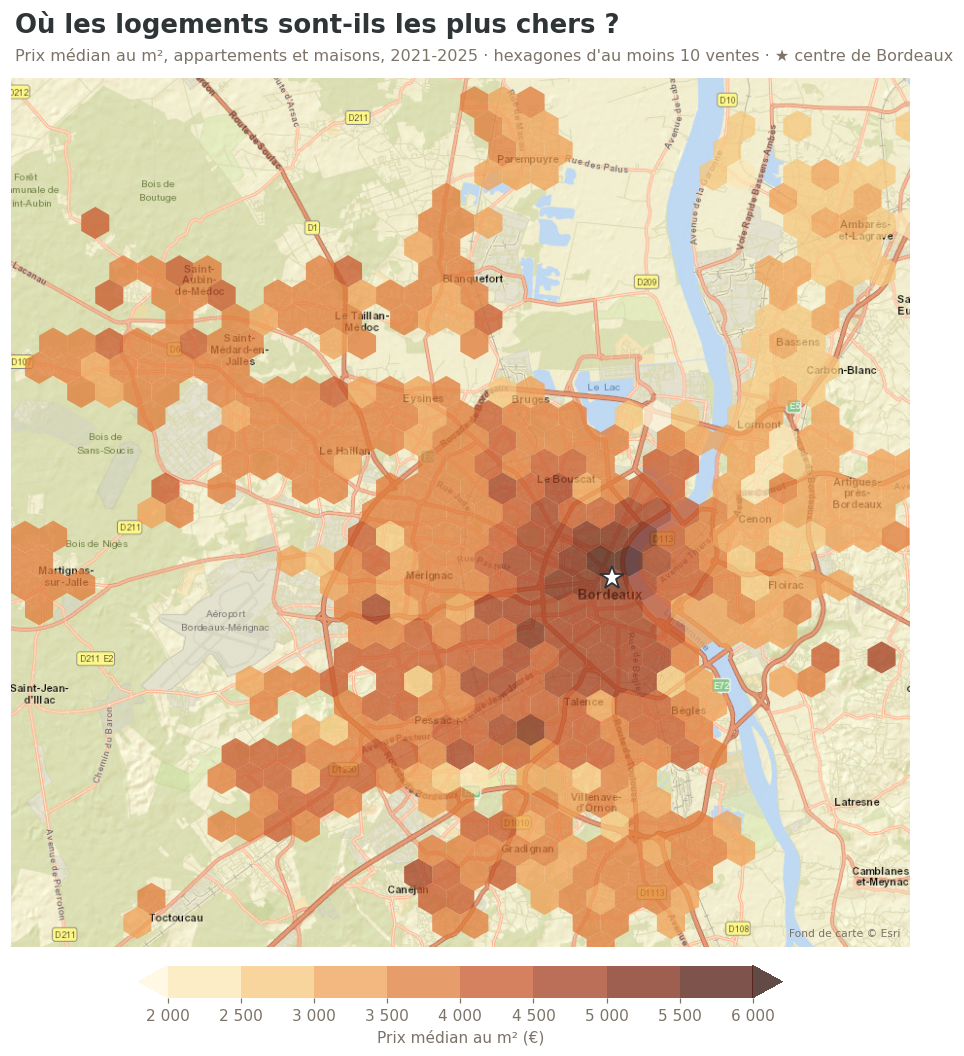

Animation enregistrée : assets/carte_prix_animation.gif


In [6]:
import contextily as cx
from PIL import Image

from src.variables import CENTRE_LAT, CENTRE_LON


def mercator(lon, lat):
    """Coordonnées GPS -> projection Web Mercator (mètres), celle des fonds de carte en ligne."""
    r = 6378137
    x = r * np.radians(lon)
    y = r * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
    return x, y


ventes["x"], ventes["y"] = mercator(ventes["longitude"], ventes["latitude"])
cx_centre, cy_centre = mercator(CENTRE_LON, CENTRE_LAT)

# Cadre fixe pour toutes les images : la métropole sans les quelques ventes isolées
xmin, xmax = ventes["x"].quantile([0.005, 0.995])
ymin, ymax = ventes["y"].quantile([0.005, 0.995])
CADRE = (xmin - 1500, xmax + 1500, ymin - 1500, ymax + 1500)


from matplotlib.colors import ListedColormap, BoundaryNorm

# Huit classes de 500 € : chaque tranche a sa propre couleur, du jaune pâle au brun foncé
BORNES = np.arange(2000, 6001, 500)
cmap_prix = ListedColormap(["#FBE7B5", "#F6C77D", "#EFA055", "#E07B39",
                            "#C8572A", "#A53D20", "#7E2A17", "#521A10"])
cmap_prix.set_under("#FFF6DD")
cmap_prix.set_over("#2E0E08")
norme_prix = BoundaryNorm(BORNES, cmap_prix.N)

# Fond de carte en couleurs d'Esri, téléchargé une seule fois pour toutes les images
tuiles, etendue = cx.bounds2img(CADRE[0], CADRE[2], CADRE[1], CADRE[3], zoom=12,
                                source=cx.providers.Esri.WorldStreetMap, ll=False)


def carte(donnees, titre, sous_titre, fichier, mincnt=10):
    """Carte des prix médians au m² sur fond de carte de Bordeaux Métropole."""
    fig, ax = plt.subplots(figsize=(9, 9.5))
    # Colle la carte sous le sous-titre au lieu de laisser la marge par défaut
    fig.subplots_adjust(top=0.9, bottom=0.02, left=0.03, right=0.97)
    ax.imshow(tuiles, extent=etendue, interpolation="bilinear", zorder=1)
    hb = ax.hexbin(donnees["x"], donnees["y"], C=donnees["prix_m2"], reduce_C_function=np.median,
                   gridsize=32, extent=CADRE, mincnt=mincnt, cmap=cmap_prix, norm=norme_prix,
                   alpha=0.75, linewidths=0, zorder=2)
    ax.set_xlim(CADRE[0], CADRE[1])
    ax.set_ylim(CADRE[2], CADRE[3])
    ax.plot(cx_centre, cy_centre, marker="*", color="white", markeredgecolor=ENCRE,
            markeredgewidth=1.2, ms=16, zorder=4)
    ax.set_axis_off()
    # Mention obligatoire de la source du fond de carte
    ax.text(0.99, 0.01, "Fond de carte © Esri", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=7, color=GRIS, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, orientation="horizontal", fraction=0.035, pad=0.02,
                        ticks=BORNES, extend="both", format=milliers)
    cbar.set_label("Prix médian au m² (€)", color=GRIS)
    cbar.outline.set_visible(False)
    # Même transparence dans la légende que sur la carte, pour que les couleurs correspondent
    cbar.solids.set_alpha(0.75)
    fig.text(0.05, 0.965, titre, fontsize=17, color=ENCRE, fontweight="bold", va="top")
    fig.text(0.05, 0.93, sous_titre, fontsize=10.5, color=GRIS, va="top")
    fig.savefig(fichier, facecolor="white", dpi=110, bbox_inches="tight")
    return fig


# 1. Carte de synthèse, 2021-2025
fig = carte(ventes, "Où les logements sont-ils les plus chers ?",
            "Prix médian au m², appartements et maisons, 2021-2025 · hexagones d'au moins 10 ventes · ★ centre de Bordeaux",
            ASSETS / "carte_prix.png")
plt.show()

# 2. Une image par année, assemblées en animation (GIF)
images = []
for annee in range(2021, 2026):
    f = carte(ventes[ventes["annee"] == annee], f"Prix médian au m² en {annee}",
              "Appartements et maisons · hexagones d'au moins 5 ventes dans l'année · ★ centre de Bordeaux",
              ASSETS / f"carte_{annee}.png", mincnt=5)
    plt.close(f)
    images.append(Image.open(ASSETS / f"carte_{annee}.png").convert("RGB"))

# Même taille pour toutes les images, la dernière reste affichée plus longtemps
taille = images[0].size
images = [im.resize(taille) for im in images]
images[0].save(ASSETS / "carte_prix_animation.gif", save_all=True, append_images=images[1:],
               duration=[1300] * 4 + [2600], loop=0)
print("Animation enregistrée : assets/carte_prix_animation.gif")

> $\color{#55623F}{\textbf{Constat}}$
>
> Le prix baisse quand on s'éloigne du centre de Bordeaux.
> À l'est de la Garonne (rive droite), les prix sont nettement plus bas qu'à distance égale sur la rive gauche.
> D'où deux choix pour le modèle : une variable **distance au centre**, et les **coordonnées** pour qu'il découpe lui-même la carte.

## $\color{#B5562F}{\mathbf{4}}$ &nbsp; Prix et surface

In [7]:
# Prix médian au m² par classe de surface, pour chaque type
bornes = [0, 30, 50, 70, 90, 120, 160, 600]
classes = ["< 30", "30-50", "50-70", "70-90", "90-120", "120-160", "≥ 160"]
ventes["classe_surface"] = pd.cut(ventes["surface_reelle_bati"], bornes, labels=classes, right=False)

tableau(ventes.groupby(["classe_surface", "type_local"], observed=True)["prix_m2"]
              .agg(**{"Prix médian (€/m²)": "median", "Ventes": "size"})
              .unstack("type_local")
              .rename_axis(index="Surface (m²)", columns=[None, None]))

> $\color{#55623F}{\textbf{Constat}}$
>
> Pour les appartements, le prix au m² suit une **courbe en U** : les studios et les grands appartements sont les plus chers au m².
> Hypothèse : les grands appartements se trouvent surtout dans les beaux quartiers. L'effet de la surface dépend donc du lieu, ce qu'un modèle linéaire capterait mal.

## $\color{#B5562F}{\mathbf{5}}$ &nbsp; Bilan

- **Tendance.** Pic mi-2022 puis baisse ; le modèle sera évalué sur 2025, un marché différent de celui où il a appris.
- **Localisation.** Facteur le plus visible : distance au centre et rive de la Garonne.
- **Type de logement.** Les maisons sont plus chères au m², probablement à cause du terrain.
- **Surface.** Effet non linéaire et lié au lieu : un argument pour les modèles à arbres.
- **Limite.** La commune seule est fragile ; la position géographique est plus fiable.